# XGBoost training and evaluation

This notebook reviews the completed experiments from `09_XGBoost.py`. Tables and figures below are loaded from the committed run. Set `RUN_TRAINING=True` to repeat training, tuning and evaluation. Development CV estimates also reflect model and threshold selection on these folds. Held-out results provide the independent evaluation.

In [1]:
from pathlib import Path
import base64
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLES = ROOT / 'reports/tables'
def show_image(name):
    display(Image(filename=str(ROOT / 'reports/figures' / name)))
print('Repository', ROOT.name)


Repository LeukoGuard_Project


## Data and validation

The 71 cleaned CBC inputs use the agreed split IDs and five development folds. Median imputation and missing indicators are learned on training folds. Class weights and optional SMOTE also use training folds only. Trees use unscaled inputs. Hospitals D-G are reserved for evaluation.

In [2]:
display(pd.read_csv(TABLES / 'V3_role_summary.csv'))
display(pd.read_csv(TABLES / 'V4_development_fold_balance.csv'))

role,n,leukemia,hospitals,prevalence_pct
development_cv,26922,8974,"A,B,C",33.333333
held_out_hospital,149623,5784,"D,E,F,G",3.865716
internal_validation,211611,7818,"A,B,C",3.694515
real_world_test,58481,2290,RW,3.915802


cv_fold,n,leukemia,prevalence_pct
0,5385,1795,33.333333
1,5385,1795,33.333333
2,5384,1795,33.339525
3,5384,1795,33.339525
4,5384,1794,33.320951


## Repeat the experiment

The optional command invokes the same pipeline used for the saved model. It evaluates the untuned baseline, searches 16 configurations by mean fold PR-AUC, applies the one-standard-error selection rule and compares balanced weighting, no weighting and SMOTE. Runtime depends on your machine.

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT / 'notebooks/09_XGBoost.py')], cwd=ROOT, check=True)
print('Reviewing saved results' if not RUN_TRAINING else 'Training completed')

Reviewing saved results


In [4]:
display(pd.read_csv(TABLES / 'XGB_baseline_cv.csv'))
display(pd.read_csv(TABLES / 'XGB_tuning.csv'))
display(pd.read_csv(TABLES / 'XGB_imbalance_comparison.csv'))

max_depth,n_estimators,learning_rate,min_child_weight,imbalance,threshold,mean_fold_ROC_AUC,mean_fold_PR_AUC,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN,flagged_%
3,100,0.1,1,none,0.486705,0.978469,0.954235,26922,33.333333,0.900045,0.902761,0.901401,0.951527,0.978439,0.95397,8077,897,870,17078,33.233044


max_depth,n_estimators,learning_rate,min_child_weight,ROC_AUC,ROC_AUC_sd,PR_AUC,PR_AUC_sd,selected
3,150,0.05,5,0.976448,0.001888,0.949155,0.005165,False
3,150,0.05,1,0.976544,0.001886,0.949376,0.005208,False
3,150,0.10,5,0.980608,0.001896,0.957329,0.005051,False
3,150,0.10,1,0.980538,0.001958,0.957403,0.004965,False
3,300,0.05,5,0.980621,0.001965,0.957457,0.005117,False
3,300,0.05,1,0.980744,0.001831,0.958106,0.004798,False
3,300,0.10,5,0.983730,0.001922,0.964302,0.004995,False
3,300,0.10,1,0.984087,0.001986,0.965331,0.004752,False
5,150,0.05,5,0.982822,0.001627,0.963315,0.004750,False
5,150,0.05,1,0.983059,0.001551,0.964348,0.004502,False


imbalance,ROC_AUC,ROC_AUC_sd,PR_AUC,PR_AUC_sd,selected
balanced,0.987458,0.001863,0.972912,0.004613,True
none,0.987518,0.001543,0.973187,0.003721,False
smote,0.987406,0.001909,0.972148,0.004782,False


## Frozen threshold and evaluation

The threshold is the highest development out-of-fold score cutoff achieving at least 90% recall. It is frozen before internal, external and real-world evaluation. PR-AUC is interpreted alongside prevalence. Recompute held-out metrics from saved predictions below to verify the published table.

In [5]:
sys.path.insert(0, str(ROOT / 'src'))
from lr_pipeline import metrics_at, threshold_for_recall
import numpy as np
oof = pd.read_csv(ROOT / 'reports/predictions/xgb_oof_development.csv')
threshold = threshold_for_recall(oof.y, oof.p_oof)
print('Frozen threshold', threshold)
display(pd.read_csv(TABLES / 'XGB_cv_fold_results.csv'))
results = pd.read_csv(TABLES / 'XGB_results_at_threshold.csv')
display(results)
held = pd.read_csv(ROOT / 'reports/predictions/xgb_eval_predictions.csv.gz')
external = held[held.cohort.eq('external_validation')]
row = results[results.cohort.eq('external_validation') & results.site.eq('pooled')].iloc[0]
for metric, value in metrics_at(external.y, external.p, threshold).items():
    np.testing.assert_allclose(row[metric], value, atol=1e-10)
print('Held-out metrics match saved predictions')

fold,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN,flagged_%
0,5385,33.333333,0.902507,0.946815,0.924130,0.974652,0.988593,0.973877,1620,175,91,3499,31.773445
1,5385,33.333333,0.899164,0.934028,0.916265,0.968245,0.984984,0.966797,1614,181,114,3476,32.089136
2,5384,33.339525,0.911978,0.939724,0.925643,0.970744,0.988924,0.975378,1637,158,105,3484,32.355126
3,5384,33.339525,0.894708,0.949173,0.921136,0.976038,0.988864,0.978562,1606,189,86,3503,31.426449
4,5384,33.320951,0.891862,0.943396,0.916905,0.973259,0.985924,0.969945,1600,194,96,3494,31.500743


cohort,site,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN,flagged_%
"development (CV, OOF)",A+B+C,26922,33.333333,0.900045,0.942584,0.920823,0.972587,0.987417,0.972706,8077,897,492,17456,31.828987
internal_validation,A,59986,4.554396,0.891288,0.477545,0.621887,0.953470,0.976615,0.567046,2435,297,2664,54590,8.500317
internal_validation,B,51227,1.821305,0.878885,0.285118,0.430559,0.959120,0.977641,0.495061,820,113,2056,48238,5.614227
internal_validation,C,100398,4.136537,0.833373,0.296040,0.436885,0.914489,0.947104,0.453985,3461,692,8230,88015,11.644654
internal_validation,pooled,211611,3.694515,0.859043,0.341503,0.488721,0.936455,0.963940,0.492334,6716,1102,12950,190843,9.293468
external_validation,D,30156,4.390503,0.848187,0.350062,0.495587,0.927685,0.953859,0.491427,1123,201,2085,26747,10.638016
external_validation,E,94318,2.699379,0.810291,0.427920,0.560065,0.969947,0.973940,0.614265,2063,483,2758,89014,5.111432
external_validation,F,20179,4.901135,0.829120,0.452789,0.585714,0.948359,0.966034,0.537329,820,169,991,18199,8.974677
external_validation,G,4970,18.611670,0.851892,0.613707,0.713445,0.877379,0.931794,0.758257,788,137,496,3549,25.835010
external_validation,pooled,149623,3.865716,0.828838,0.430960,0.567069,0.955992,0.968186,0.579778,4794,990,6330,137509,7.434686


Frozen threshold 0.7538499236106873
Held-out metrics match saved predictions


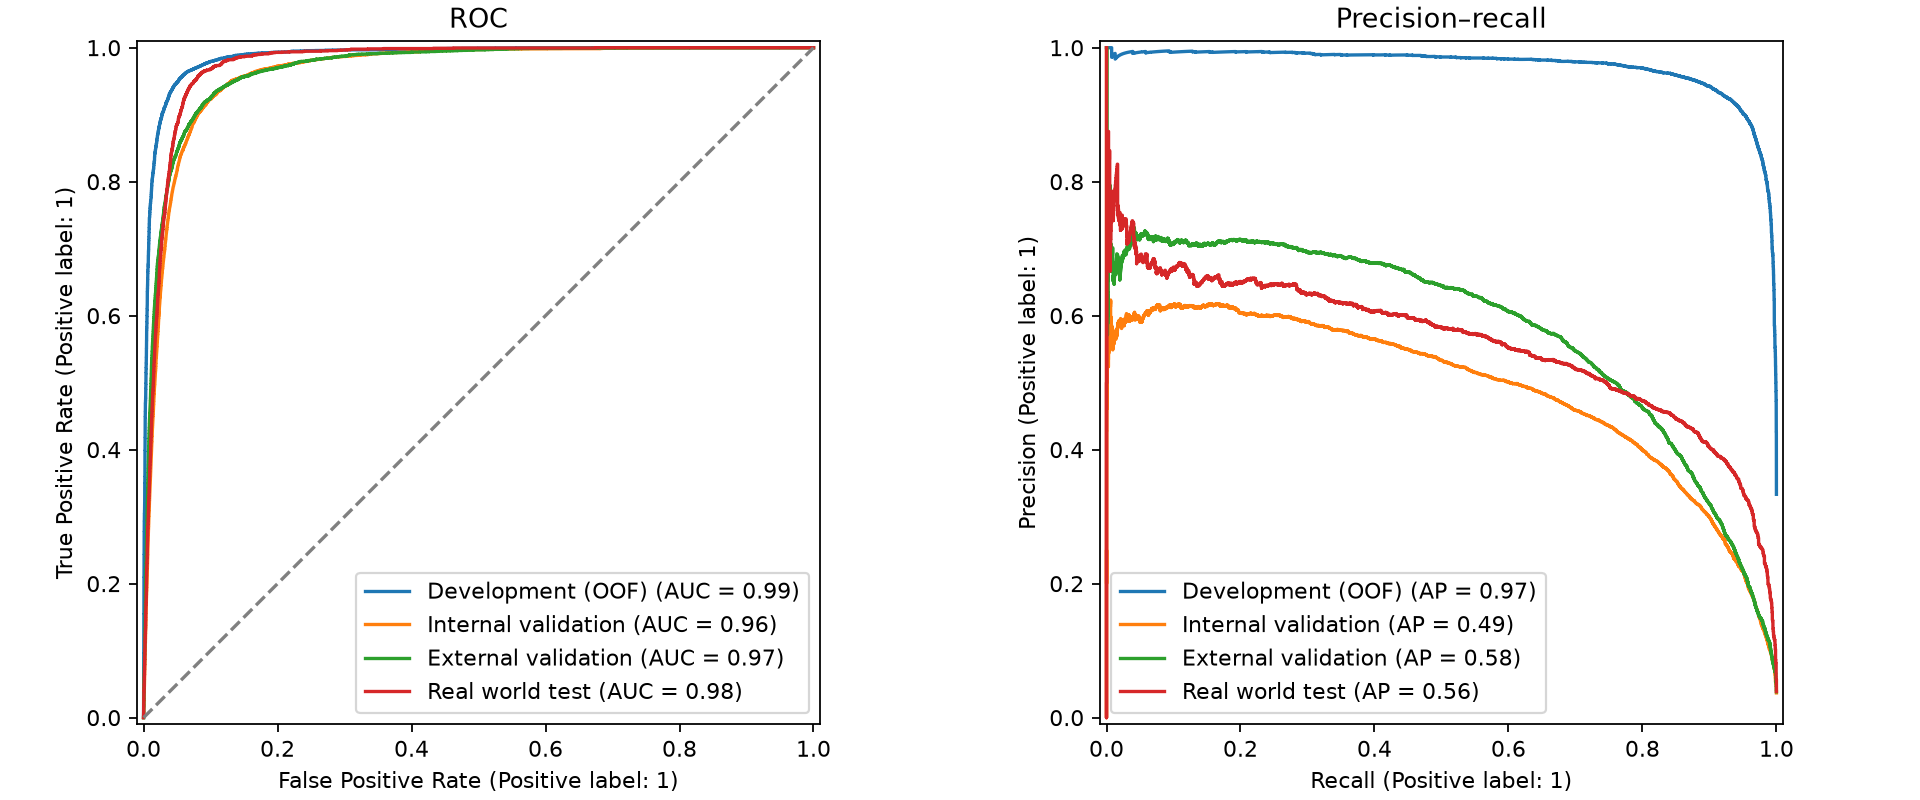

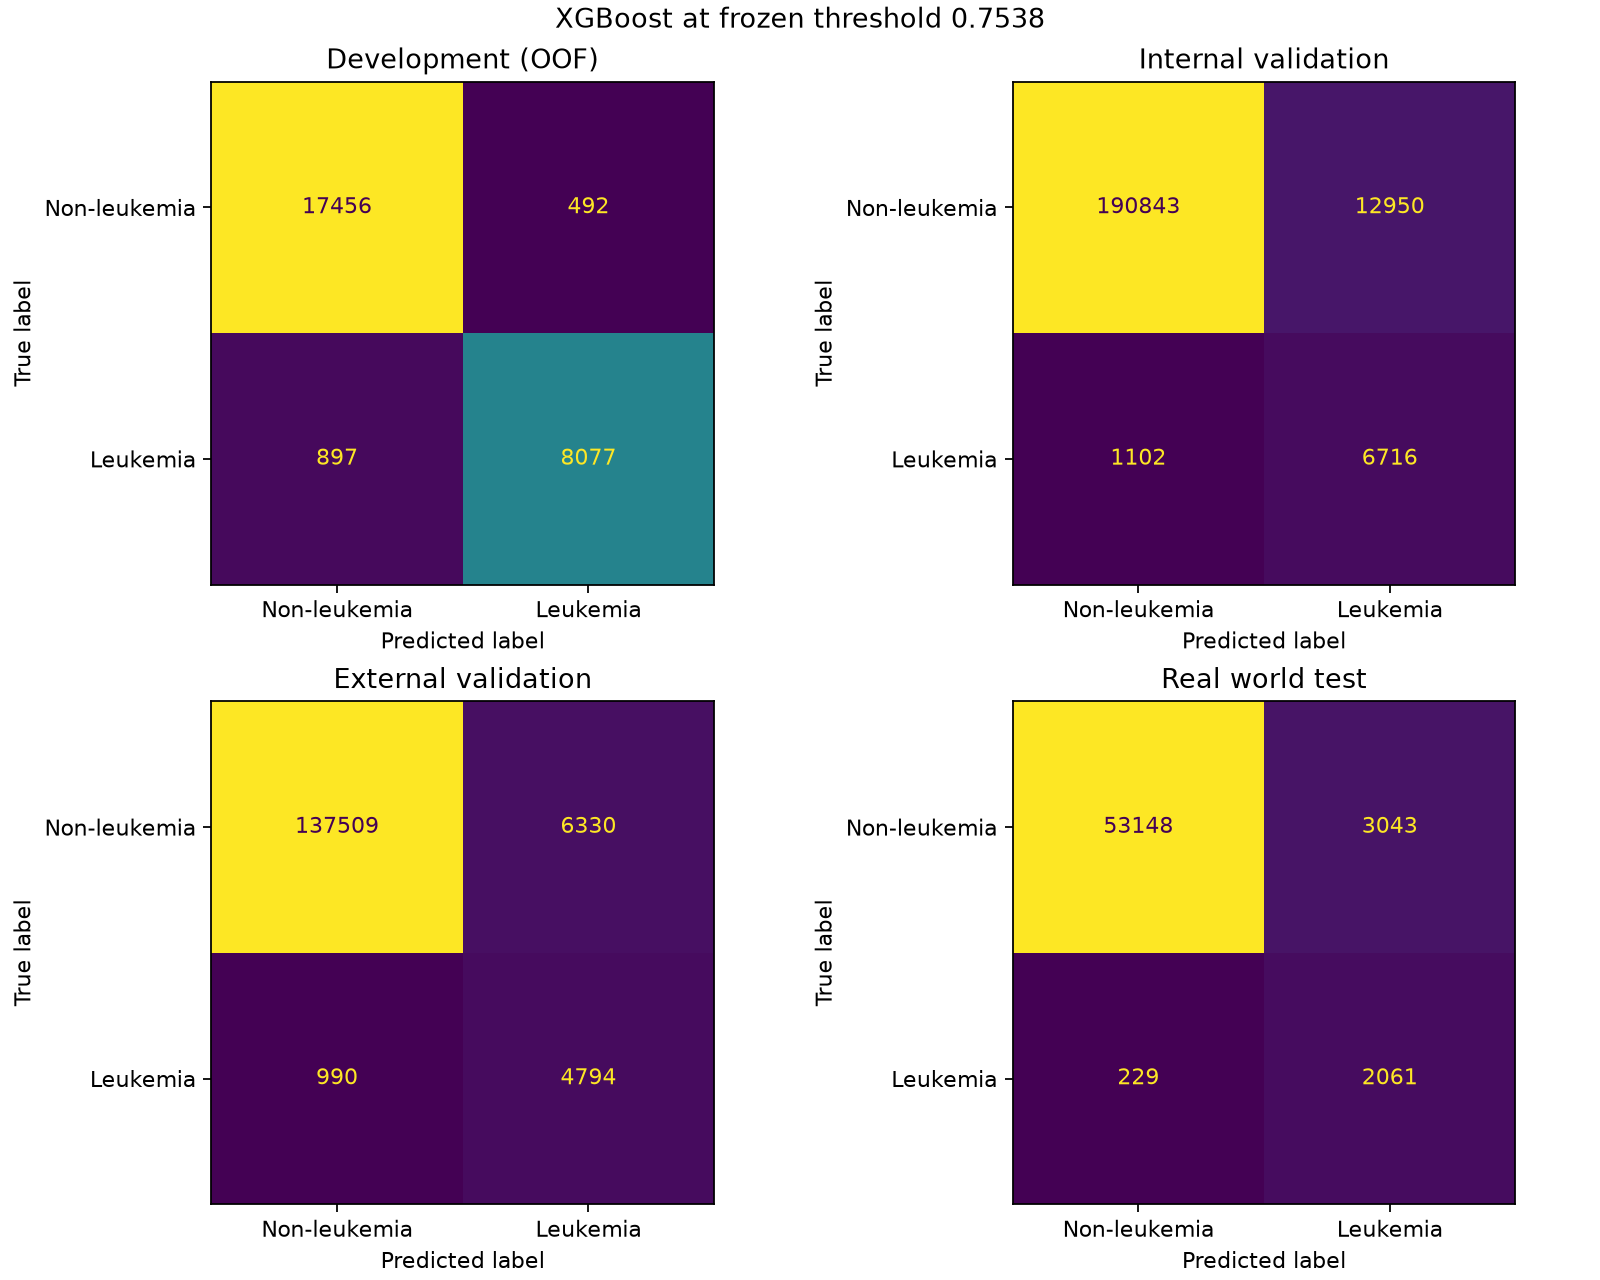

model,cohort,site,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN,flagged_%
Logistic Regression,"development (CV, OOF)",A+B+C,26922,33.333333,0.900045,0.867841,0.883650,0.931469,0.967779,0.929604,8077,897,1230,16718,34.570240
Logistic Regression,internal_validation,pooled,211611,3.694515,0.897800,0.287428,0.435449,0.914614,0.961568,0.491190,7019,799,17401,186392,11.540043
Logistic Regression,external_validation,pooled,149623,3.865716,0.882607,0.297131,0.444590,0.916045,0.959545,0.529248,5105,679,12076,131763,11.482860
Logistic Regression,real_world_test,RW,58481,3.915802,0.935371,0.314907,0.471183,0.917069,0.966787,0.478039,2142,148,4660,51531,11.631128
Random Forest,"development (CV, OOF)",A+B+C,26922,33.333333,0.900045,0.919408,0.909623,0.960553,0.981583,0.960356,8077,897,708,17240,32.631305
Random Forest,internal_validation,pooled,211611,3.694515,0.880404,0.382453,0.533256,0.945464,0.969835,0.558992,6883,935,11114,192679,8.504756
Random Forest,external_validation,pooled,149623,3.865716,0.843880,0.437366,0.576133,0.956347,0.972040,0.618927,4881,903,6279,137560,7.458746
Random Forest,real_world_test,RW,58481,3.915802,0.914410,0.386489,0.543332,0.940845,0.973954,0.555386,2094,196,3324,52867,9.264547
XGBoost,"development (CV, OOF)",A+B+C,26922,33.333333,0.900045,0.942584,0.920823,0.972587,0.987417,0.972706,8077,897,492,17456,31.828987
XGBoost,internal_validation,pooled,211611,3.694515,0.859043,0.341503,0.488721,0.936455,0.963940,0.492334,6716,1102,12950,190843,9.293468


In [6]:
show_image('XGB_roc_pr.png')
show_image('XGB_confusion_matrices.png')
display(pd.read_csv(TABLES / 'FINAL_model_comparison_headline.csv'))

## Interpretation and limitations

XGBoost has held-out ROC-AUC 0.9682 and PR-AUC 0.5798. Recall falls from the development target of 90% to 82.9% on D-G. Random Forest leads on held-out ROC-AUC and PR-AUC, while Logistic Regression has the highest recall at the frozen thresholds. Greater model flexibility may capture development patterns that transfer less well, but this explanation requires further experiments. Patient identifiers are unavailable, so the split checks cannot exclude repeated tests from the same patient. See `docs/member3_results_summary.md` for the detailed RQ2 discussion.